# Trial five: parameters the papers did not take into account

The model contains choices that the papers do not discuss or did not test. Does any of them change the behaviour a lot? We start from the Puckett model (A4) with 20 fish at 1 BL/s and change **one thing at a time**. The options are in `study_code/study_model.py`, with their tests in `study_code/test_study_model.py`. The story is in [chapter 5 of the README](../README.md#chapter-5-trial-five-parameters-the-papers-did-not-take-into-account).

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the checks folder (it contains study_code/) and let Python import the shared study code.
CHECKS_FOLDER = Path.cwd()
while not (CHECKS_FOLDER / "study_code" / "study_tools.py").is_file():
    if CHECKS_FOLDER == CHECKS_FOLDER.parent:
        raise FileNotFoundError("study_code/study_tools.py was not found in this folder or any parent folder.")
    CHECKS_FOLDER = CHECKS_FOLDER.parent
sys.path.insert(0, str(CHECKS_FOLDER / "study_code"))

import study_tools
from study_tools import (
    PUCKETT_SETTINGS, OPTION_DEFAULTS, PUCKETT_COLOR, EXTRA_COLOR,
    change_settings, final_label_counts, load_results, run_many, short_table, summarize, translate,
)

# Where this trial keeps its saved results and its README figure.
DATA_FOLDER = CHECKS_FOLDER / "trial_five_parameters_not_in_papers" / "data"
FIGURE_FOLDER = CHECKS_FOLDER / "trial_five_parameters_not_in_papers" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

## Settings

Each change has a number, a parameter, a value and the model options it sets. The parameter and value names are saved in the CSV file in Spanish (the saved results use them as keys); the tables show the English names below.

- **Start "25 % central":** the fish start in a central square whose side is 25 % of the arena side (7 × 7 BL).
- **8b (extra):** like 8, but without the silent gap between repulsion and attraction (r_o = 0.51 BL), so attraction starts right after repulsion, as in Couzin's swarm.

In [2]:
SEEDS = list(range(10))

# (number, parameter, value, model options), all compared with the base A4.
CHANGES = [
    (1, "tamaño de arena", "20", {"arena": 20.0}),
    (1, "tamaño de arena", "40", {"arena": 40.0}),
    (2, "inicio", "25 % central", {"initial_spread": 0.25}),
    (3, "orden de actualización", "uno por uno", {"update": "asynchronous"}),
    (4, "vecinos", "k = 4", {"neighbour_mode": "topological", "k_neighbours": 4}),
    (4, "vecinos", "k = 7", {"neighbour_mode": "topological", "k_neighbours": 7}),
    (5, "combinación", "normalizada", {"social_combination": "normalized"}),
    (6, "velocidad propia de cada pez", "10 %", {"speed_sd": 0.1}),
    (6, "velocidad propia de cada pez", "30 %", {"speed_sd": 0.3}),
    (7, "regulación de velocidad", "ganancia 0.1", {"speed_gain": 0.1}),
    (7, "regulación de velocidad", "ganancia 0.3", {"speed_gain": 0.3}),
]

# 8 and 8b: no orientation, with three strengths of speed regulation (Katz et al. 2011).
NO_ORIENTATION_GAINS = [0.0, 0.1, 0.3]
NO_GAP_ORIENTATION_RADIUS = 0.51

# Extra: the base again, but three times longer (540 BL of swimming instead of 180).
LONGER_SWIM_DISTANCE = 3 * study_tools.SWIM_DISTANCE

# Relevance criterion of the plan, fixed before running.
UNIT_CHANGE = 0.1        # polarization, rotation, largest group: change of more than 0.1
DISTANCE_CHANGE = 0.2    # nearest-neighbour and centre distance: change of more than 20 %
ERROR_FACTOR = 2         # and the change must be larger than 2 standard errors of the difference
UNIT_METRICS = ["polarization", "rotation", "largest_group_fraction"]
DISTANCE_METRICS = ["nnd", "centroid_distance"]

# English names for the saved parameter and value names.
PARAMETER_NAMES = {
    "base": "base",
    "tamaño de arena": "arena size (BL)",
    "inicio": "start",
    "orden de actualización": "update order",
    "vecinos": "topological neighbours",
    "combinación": "orientation + attraction",
    "velocidad propia de cada pez": "own speed per fish (sd)",
    "regulación de velocidad": "speed regulation",
    "sin orientación + regulación": "no orientation + speed regulation",
    "sin orientación + regulación, sin hueco": "no orientation + speed regulation, no gap",
}
VALUE_NAMES = {"25 % central": "central 25 %", "uno por uno": "one by one", "normalizada": "normalized",
               "ganancia 0": "gain 0", "ganancia 0.1": "gain 0.1", "ganancia 0.3": "gain 0.3"}

The configurations: the base, the 11 changes, 8, 8b and the longer extra run.

In [3]:
base = change_settings(PUCKETT_SETTINGS, "base (A4)", OPTION_DEFAULTS)
base["parameter"] = "base"
base["value"] = "base"


def variant(number, parameter, value, changes):
    """The base configuration with some changes, labelled with its parameter and value."""
    settings = change_settings(base, f"{number}. {parameter}: {value}", changes)
    settings["parameter"] = parameter
    settings["value"] = value
    return settings


trial_runs = [base]
for number, parameter, value, changes in CHANGES:
    trial_runs.append(variant(number, parameter, value, changes))
for gain in NO_ORIENTATION_GAINS:
    changes = {"rules": "repulsion+attraction", "speed_gain": gain}
    trial_runs.append(variant(8, "sin orientación + regulación", f"ganancia {gain:g}", changes))
for gain in NO_ORIENTATION_GAINS:
    changes = {"rules": "repulsion+attraction", "speed_gain": gain, "orientation_radius": NO_GAP_ORIENTATION_RADIUS}
    trial_runs.append(variant("8b", "sin orientación + regulación, sin hueco", f"ganancia {gain:g}", changes))

longer = change_settings(base, "base (A4), 540 BL de nado", {"swim_distance": LONGER_SWIM_DISTANCE})


def english_label(settings):
    """English name of a configuration, for tables and figures."""
    if settings["parameter"] == "base":
        return settings["label"]
    number = settings["label"].split(".")[0]
    parameter = PARAMETER_NAMES[settings["parameter"]]
    value = translate([settings["value"]], VALUE_NAMES)[0]
    return f"{number}. {parameter}: {value}"


LABEL_NAMES = {longer["label"]: "base (A4), 540 BL of swimming"}
for settings in trial_runs:
    LABEL_NAMES[settings["label"]] = english_label(settings)

## Run or load

The 18 configurations with 10 seeds (180 simulations) and the longer extra run.

In [4]:
results = run_many(trial_runs, SEEDS, DATA_FOLDER / "results.csv")
longer_results = run_many([longer], SEEDS, DATA_FOLDER / "extra_longer_runs.csv")

Loaded saved results from results.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from extra_longer_runs.csv (set study_tools.RERUN = True to simulate again).


Check: the base is the same configuration with the same seeds as the base of trial seven, so it must give exactly the same numbers.

In [5]:
trial_seven = load_results(CHECKS_FOLDER / "trial_seven_minimum_parameters" / "data" / "part_b_sensitivity.csv")
theirs = trial_seven[trial_seven["label"] == "base (A4)"].sort_values("seed")["polarization"].to_numpy()
ours = results[results["label"] == "base (A4)"].sort_values("seed")["polarization"].to_numpy()
assert np.array_equal(theirs, ours)
print("Check passed: trial five base = trial seven base, seed by seed.")

Check passed: trial five base = trial seven base, seed by seed.


## Results tables

Mean ± standard error over the 10 seeds.

In [6]:
summary = summarize(results, ["label", "parameter", "value"])
summary["name"] = translate(summary["label"], LABEL_NAMES)
table = short_table(summary, "name")
table["largest group"] = study_tools.mean_and_error_text(summary, "largest_group_fraction")
table["distance to centre (BL)"] = study_tools.mean_and_error_text(summary, "centroid_distance")
table

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL),largest group,distance to centre (BL)
0,base (A4),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01,0.93 ± 0.03,3.02 ± 0.87
1,1. arena size (BL): 20,9/10,0.96 ± 0.01,0.04 ± 0.01,0.60 ± 0.02,0.99 ± 0.01,0.00 ± 0.00,0.27 ± 0.01,0.99 ± 0.00,1.24 ± 0.06
2,1. arena size (BL): 40,4/10,0.86 ± 0.04,0.26 ± 0.08,0.73 ± 0.13,0.53 ± 0.15,0.00 ± 0.00,0.28 ± 0.01,0.84 ± 0.06,5.28 ± 1.49
3,2. start: central 25 %,10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01,1.00 ± 0.00,1.13 ± 0.01
4,3. update order: one by one,6/10,0.83 ± 0.07,0.20 ± 0.08,0.61 ± 0.01,0.71 ± 0.14,0.00 ± 0.00,0.38 ± 0.01,0.88 ± 0.06,3.64 ± 1.27
5,4. topological neighbours: k = 4,6/10,0.78 ± 0.10,0.25 ± 0.11,0.62 ± 0.01,0.68 ± 0.14,0.00 ± 0.00,0.27 ± 0.02,0.87 ± 0.06,4.46 ± 1.55
6,4. topological neighbours: k = 7,6/10,0.90 ± 0.03,0.26 ± 0.08,0.75 ± 0.08,0.66 ± 0.15,0.00 ± 0.00,0.29 ± 0.01,0.90 ± 0.04,3.28 ± 0.89
7,5. orientation + attraction: normalized,7/10,0.85 ± 0.06,0.20 ± 0.10,0.62 ± 0.03,0.78 ± 0.13,0.00 ± 0.00,0.28 ± 0.01,0.92 ± 0.04,3.27 ± 1.26
8,6. own speed per fish (sd): 10 %,8/10,0.84 ± 0.06,0.19 ± 0.09,0.68 ± 0.03,0.80 ± 0.13,0.00 ± 0.00,0.28 ± 0.01,0.94 ± 0.05,2.44 ± 0.88
9,6. own speed per fish (sd): 30 %,9/10,0.81 ± 0.01,0.12 ± 0.01,0.79 ± 0.07,0.96 ± 0.03,0.01 ± 0.00,0.22 ± 0.01,0.98 ± 0.01,1.70 ± 0.11


In [7]:
results["name"] = translate(results["label"], LABEL_NAMES)
final_label_counts(results, "name")

label_final,polarized,milling,swarm,fragmented
name,,,,
base (A4),6,0,0,4
1. arena size (BL): 20,9,0,0,1
1. arena size (BL): 40,4,0,0,6
2. start: central 25 %,10,0,0,0
3. update order: one by one,6,0,0,4
4. topological neighbours: k = 4,6,0,0,4
4. topological neighbours: k = 7,6,0,0,4
5. orientation + attraction: normalized,7,0,0,3
6. own speed per fish (sd): 10 %,8,0,0,2


**Is a change relevant?** We compare each value with its reference: the base for 1–7, and "gain 0" of the same group for 8 and 8b (to see what speed regulation adds when there is no orientation). A value is relevant if the verdict "works in more than half of the seeds" changes, or polarization, rotation or the largest group change by more than 0.1, or a distance changes by more than 20 %, and the change is larger than 2 standard errors of the difference, √(SE_reference² + SE_value²).

In [8]:
def error_of_difference(reference, row, metric):
    """Standard error of the difference between two configurations."""
    return np.sqrt(reference[metric + "_se"] ** 2 + row[metric + "_se"] ** 2)


def what_changed(reference, row):
    """The changes that make this value relevant (an empty list = not relevant)."""
    reasons = []
    verdict_changes = (reference["works"] > 0.5) != (row["works"] > 0.5)
    works_change = row["works"] - reference["works"]
    if verdict_changes and abs(works_change) > ERROR_FACTOR * error_of_difference(reference, row, "works"):
        reasons.append(f"works: {reference['works']:.0%} -> {row['works']:.0%}")
    for metric in UNIT_METRICS:
        change = row[metric] - reference[metric]
        if abs(change) > UNIT_CHANGE and abs(change) > ERROR_FACTOR * error_of_difference(reference, row, metric):
            reasons.append(f"{metric} {change:+.2f}")
    for metric in DISTANCE_METRICS:
        change = row[metric] - reference[metric]
        relative = change / reference[metric]
        if abs(relative) > DISTANCE_CHANGE and abs(change) > ERROR_FACTOR * error_of_difference(reference, row, metric):
            reasons.append(f"{metric} {relative:+.0%}")
    return reasons


def reference_for(row):
    """The base for 1-7; "gain 0" (saved as "ganancia 0") of the same group for 8 and 8b."""
    if row["parameter"].startswith("sin orientación"):
        same_group = summary[(summary["parameter"] == row["parameter"]) & (summary["value"] == "ganancia 0")]
        return same_group.iloc[0]
    return summary[summary["parameter"] == "base"].iloc[0]


relevance_rows = []
for index in range(len(summary)):
    row = summary.iloc[index]
    if row["parameter"] == "base" or row["value"] == "ganancia 0":
        continue
    reasons = what_changed(reference_for(row), row)
    relevance_rows.append({"configuration": row["name"], "relevant": len(reasons) > 0,
                           "what changed": "; ".join(reasons)})
pd.DataFrame(relevance_rows)

,configuration,relevant,what changed
0,1. arena size (BL): 20,True,centroid_distance -59%
1,1. arena size (BL): 40,False,
2,2. start: central 25 %,True,centroid_distance -62%
3,3. update order: one by one,False,
4,4. topological neighbours: k = 4,False,
5,4. topological neighbours: k = 7,False,
6,5. orientation + attraction: normalized,False,
7,6. own speed per fish (sd): 10 %,False,
8,6. own speed per fish (sd): 30 %,True,nnd +31%
9,7. speed regulation: gain 0.1,False,


**Extra: do the failing seeds only need more time?** The base again, seed by seed, after 180 BL and after 540 BL of swimming.

In [9]:
base_runs = results[results["label"] == "base (A4)"].sort_values("seed")
longer_runs = longer_results.sort_values("seed")
pd.DataFrame({
    "seed": SEEDS,
    "works after 180 BL": base_runs["works"].to_numpy(),
    "works after 540 BL": longer_runs["works"].to_numpy(),
    "time together after 540 BL": longer_runs["together_fraction"].to_numpy(),
})

,seed,works after 180 BL,works after 540 BL,time together after 540 BL
0,0,True,True,1.0
1,1,True,True,1.0
2,2,False,True,1.0
3,3,False,True,1.0
4,4,False,True,1.0
5,5,True,True,1.0
6,6,True,True,1.0
7,7,True,True,1.0
8,8,False,True,1.0
9,9,True,True,1.0


## Figure

**The README figure.** Each dot is one configuration (mean ± standard error). The grey line is the base A4; green dots are the references of 8 and 8b (gain 0).

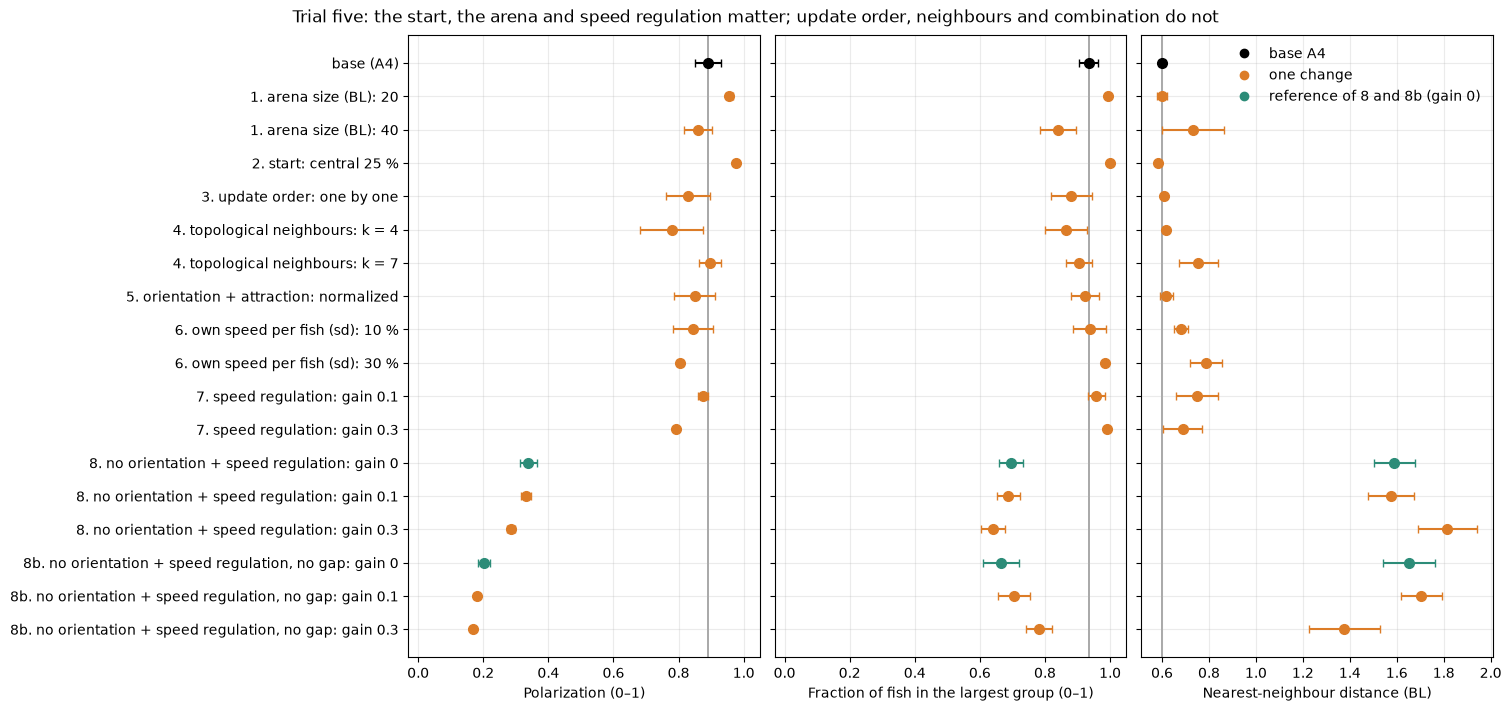

In [10]:
panels = [("polarization", "Polarization (0–1)"),
          ("largest_group_fraction", "Fraction of fish in the largest group (0–1)"),
          ("nnd", "Nearest-neighbour distance (BL)")]
base_row = summary[summary["parameter"] == "base"].iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 7), sharey=True, constrained_layout=True)
for axis, (column, axis_label) in zip(axes, panels):
    axis.axvline(base_row[column], color="0.6", linewidth=1.2, zorder=0)
    for index in range(len(summary)):
        row = summary.iloc[index]
        color = PUCKETT_COLOR
        if row["parameter"] == "base":
            color = "black"
        elif row["value"] == "ganancia 0":
            color = EXTRA_COLOR
        axis.errorbar(row[column], index, xerr=row[column + "_se"], color=color, marker="o", markersize=7, capsize=3)
    axis.set_xlabel(axis_label)
    axis.grid(alpha=0.25)
    if column != "nnd":
        axis.set_xlim(-0.03, 1.05)
axes[0].set_yticks(list(range(len(summary))))
axes[0].set_yticklabels(summary["name"])
axes[0].invert_yaxis()
# Empty plots only create the legend entries for the three colours.
axes[2].plot([], [], "o", color="black", label="base A4")
axes[2].plot([], [], "o", color=PUCKETT_COLOR, label="one change")
axes[2].plot([], [], "o", color=EXTRA_COLOR, label="reference of 8 and 8b (gain 0)")
axes[2].legend(frameon=False, loc="upper right")
fig.suptitle("Trial five: the start, the arena and speed regulation matter; update order, neighbours and combination do not")
fig.savefig(FIGURE_FOLDER / "study_02_parameters.png", dpi=150)
plt.show()

## Conclusion

- **Relevant:** a compact start and a smaller arena (both because the group assembles sooner), own speeds per fish (larger nearest-neighbour distance) and speed regulation (a more compact group).
- **Not relevant:** update order, topological neighbours and the way orientation and attraction are added. Without orientation there is never a school, even with speed regulation.
- **Extra:** with three times more swimming, the base works in 10 of 10 seeds, so the failing seeds were only still assembling.